### ** Master Seed **

In [44]:
MASTER_SEED = 2025

### Helper functions

In [45]:
from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.circuit.library.standard_gates import RYGate
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram

from qiskit.visualization import plot_bloch_multivector
from qiskit_textbook.tools import array_to_latex

def normalize_amplitude(v):
    arr = np.array(v, dtype=float)
    norm = np.linalg.norm(arr)
    if norm == 0:
        raise ValueError("Cannot amplitude-normalize: vector norm is zero.")
    return (arr / norm).tolist()

def get_a(ip):
    a = []
    for i in range(len(ip)):
        a.append((ip[i])**2)
    return a

In [46]:
import hashlib
import numpy as np

def make_seed(name, master_seed=MASTER_SEED):
    msg = f"{name}_{master_seed}".encode("utf-8")
    digest = hashlib.sha256(msg).hexdigest()
    
    # Convert hex digest to integer seed within 32-bit range
    seed = int(digest, 16) % (2**32)
    return seed

In [47]:
def normalize_sum(v):
    # Convert to float to avoid integer division issues
    v = [float(x) for x in v]
    
    s = sum(v)
    if s == 0:
        raise ValueError("Cannot normalize: sum of vector components is zero.")
    
    return [x / s for x in v]


In [48]:
def get_Ry(x0,x1):
    r = np.sqrt((x0**2)+(x1**2))
    if r > 0:
        alpha = 2*np.arcsin(x1/r)
    else:
        alpha = 2*np.pi - 2*np.arcsin(x1/r)
    return r, alpha

In [49]:
def calculateRy(a):
    angles = []
    cal = a
    while len(cal) != 1:
        cal1 = cal
        cal = []
        for i in range(int(len(cal1)/2)):
            theta = 0
            r, theta = get_Ry(cal1[2*i], cal1[2*i+1])
            cal.append(r)
            angles.append(theta)
    return angles

In [50]:
def repositionVector(a):
    b = []
    N = len(a) + 1
    i = 1
    while i != N:
        b.append(a[(N-2*i):(N-i)])
        i = i*2
    flat = np.concatenate(b)
    return flat
    

In [51]:
def int_to_reversed_bitstring(n, num_bits=None):
    if num_bits is None:
        bitstring = format(n, "b")        # no padding
    else:
        bitstring = format(n, f"0{num_bits}b")
    return bitstring[::-1]


In [52]:
def make_list(i):
    return list(range(i+1))

In [53]:
def processData(ip):
    b = normalize_amplitude(ip)
    print("Data normalized:")
    print(np.array2string(np.array(b), precision=4))
    a = get_a(b)
    return a,b

In [54]:
def generate_random_data(N, seed, low=-1.0, high=1.0):
    rng = np.random.default_rng(seed)
    return rng.uniform(low, high, 2**N)

## 0. Data - N = power of 2. If smaller then fill with 0 or 0.000001

In [55]:
number_of_qubits = 6

In [56]:
ip = generate_random_data(number_of_qubits, low=-50, high=50, seed=make_seed("Data generation"))
a,x = processData(ip)

Data normalized:
[ 0.1486 -0.1828  0.0053 -0.1224  0.0235 -0.0428  0.0063  0.1506  0.121
  0.1545  0.1416  0.087  -0.1109 -0.1702 -0.0222  0.2017 -0.1737  0.1481
  0.1195  0.1146  0.0306  0.2101 -0.1363  0.1812 -0.1941  0.1975 -0.1918
  0.1739  0.1798 -0.1986 -0.0471  0.1069  0.038   0.2064  0.1439  0.0552
 -0.0816 -0.0381  0.0735  0.1124 -0.0833  0.1352 -0.0265 -0.0486  0.0067
  0.0909  0.036  -0.0346 -0.0581  0.0514  0.1328 -0.1297 -0.1022 -0.0821
  0.1178  0.0179  0.1258  0.1925  0.0734 -0.1322  0.1143  0.1153 -0.1419
  0.1534]


<h2 style="color:yellow; font-weight:bold">1. Exact Circuit</h2>

### 1.1 Circuit Builder

This algorithm is based on the divide-and-conquer method presented in paper number 4 below

In [57]:
def build_sp_circuit(a, x,
                     calculateRy,
                     repositionVector,
                     int_to_reversed_bitstring,
                     make_list):
    """
    Build the SP (staircase) amplitude-encoding circuit using your original code.

    Args:
        a : amplitude vector
        x : input vector for calculateRy
        calculateRy : function x -> raw Ry angles
        repositionVector : function to reorder the angle vector
        int_to_reversed_bitstring : function(j, i) -> control state string
        make_list : function(i) -> list of qubit indices for qc.append

    Returns:
        qc : QuantumCircuit
    """

    c = np.array(calculateRy(x))
    Ry_angles = repositionVector(c)

    qc = QuantumCircuit(np.log2(len(a)))
    qc.ry(Ry_angles[0],0)
    for i in range(1, int(np.log2(len(a)))):
        for j in range(2**i):
            if Ry_angles[(2**i)-1+j] == 0 or np.isnan(Ry_angles[(2**i)-1+j]):
                continue
            ry = RYGate(Ry_angles[(2**i)-1+j]).control(i, ctrl_state=int_to_reversed_bitstring(j,i))
            qc.append(ry,make_list(i))

    return qc


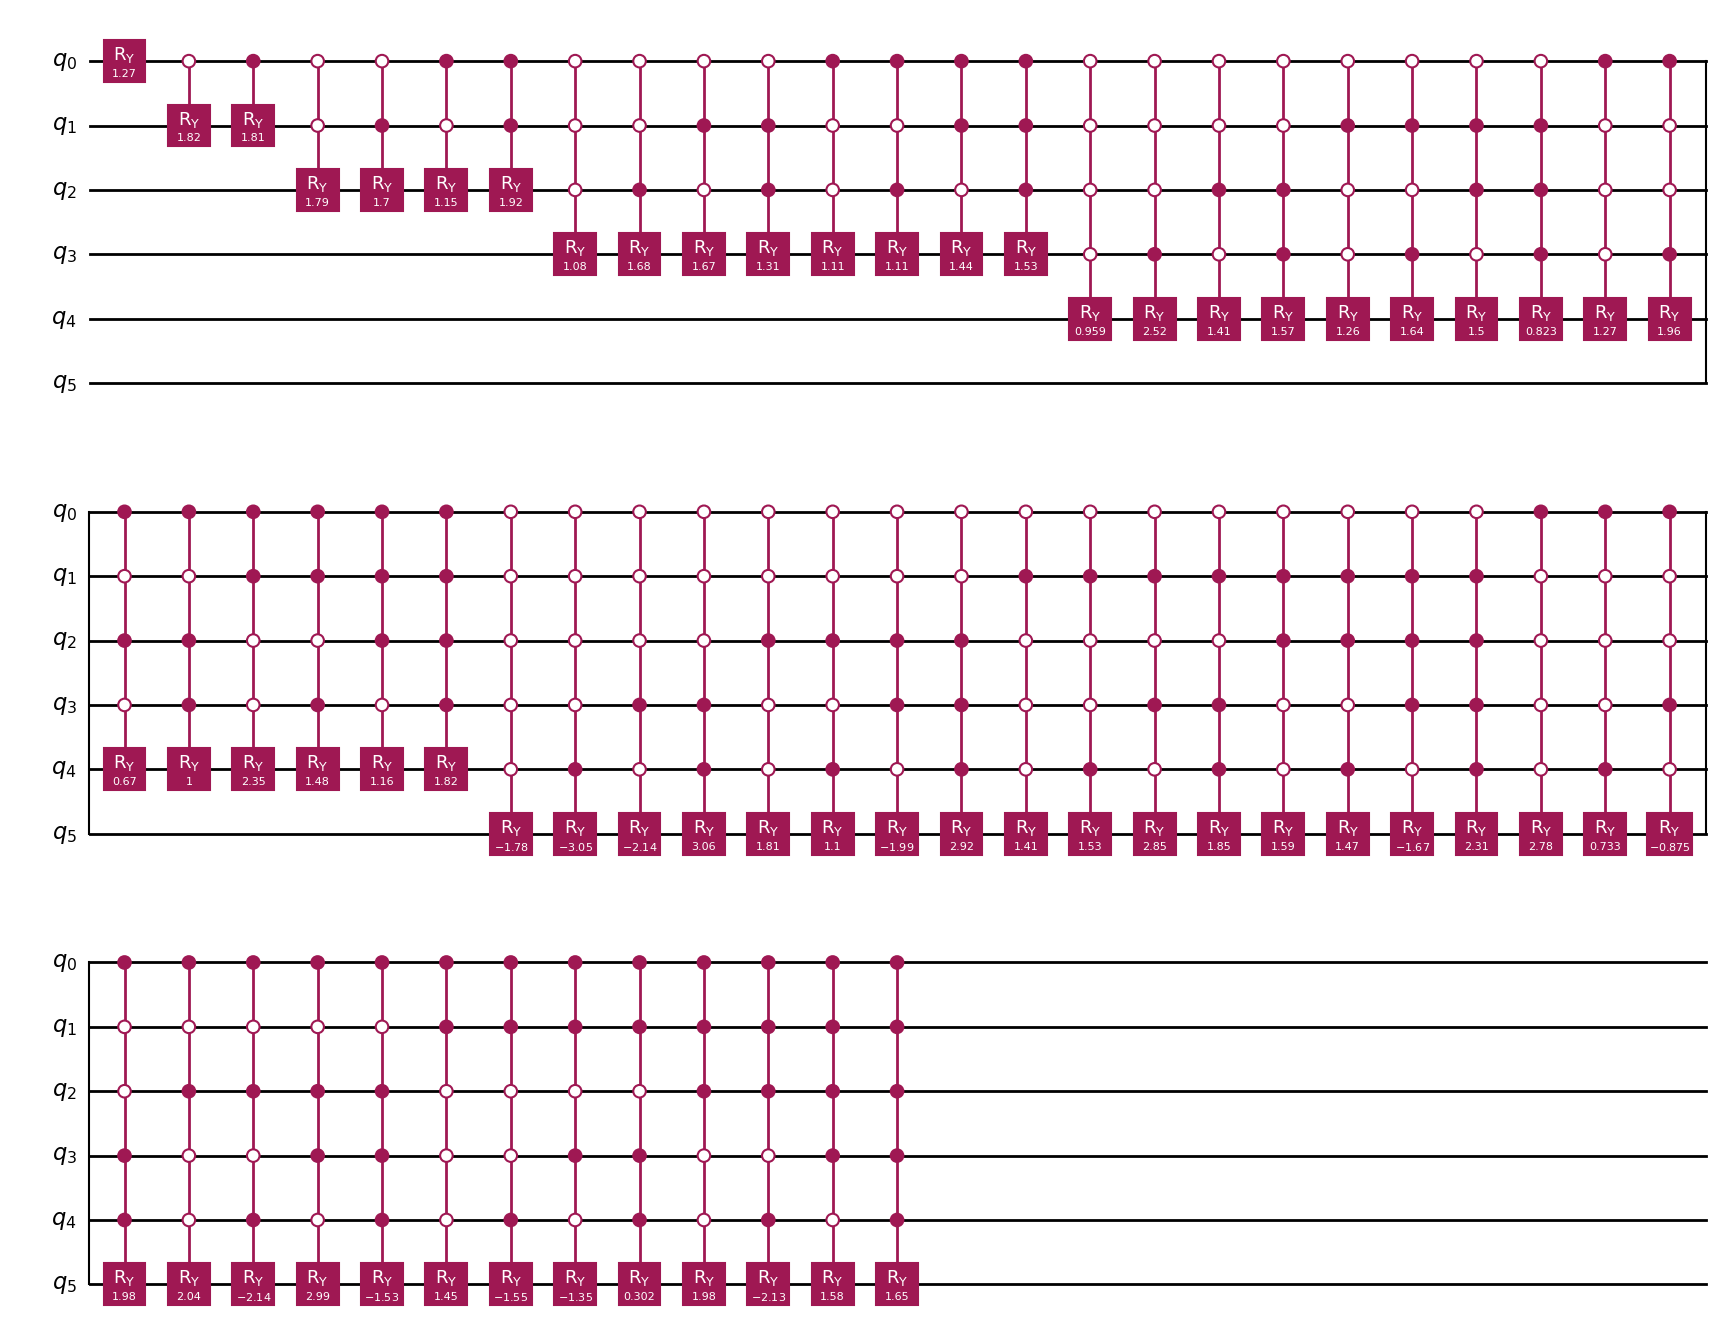

In [58]:
qc = build_sp_circuit(
    a,
    x,
    calculateRy,
    repositionVector,
    int_to_reversed_bitstring,
    make_list
)

qc.draw("mpl")

#### Decomposed Circuit & depth

In [59]:
qc.decompose(reps=3).depth()

3037

In [60]:
qc.decompose(reps=3).num_nonlocal_gates()

1860

### 1.2 Final state vector

In [61]:
simulator = Aer.get_backend("statevector_simulator")
transpiled_qc = transpile(qc,backend=simulator)
job = simulator.run(transpiled_qc)
result = job.result().get_statevector()
target = result
print(array_to_latex(result, pretext="\\text{Statevector of encoded data} = "))

<IPython.core.display.Math object>

None


<h2 style="color:red; font-weight:bold">2. Approximate Circuit</h2>


---------------------------------------------
### 2.1 Circuit builder 
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [62]:
from qiskit.circuit import ParameterVector, Parameter
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.optimizers import COBYLA, SPSA


In [63]:
def build_app_circuit(num_qubits, num_layers):

    qc_app = QuantumCircuit(num_qubits)
    n_params = num_layers * num_qubits * 2
    training_params = ParameterVector("θ", n_params)

    for layer in range(num_layers):
        base = num_qubits * 2 * layer   # starting index for this layer

        # --- RY block ---
        for q in range(num_qubits):
            qc_app.ry(training_params[base + q], q)

        # --- CRY entangler block ---
        cry_base = base + num_qubits  # start of CRY params
        for q in range(num_qubits):
            control = q
            target_qubit = 0 if q == num_qubits - 1 else q + 1
            qc_app.cry(training_params[cry_base + q], control, target_qubit)

        qc_app.barrier()

    return qc_app, training_params

#### Generating Circuit

Insert the number of layers here

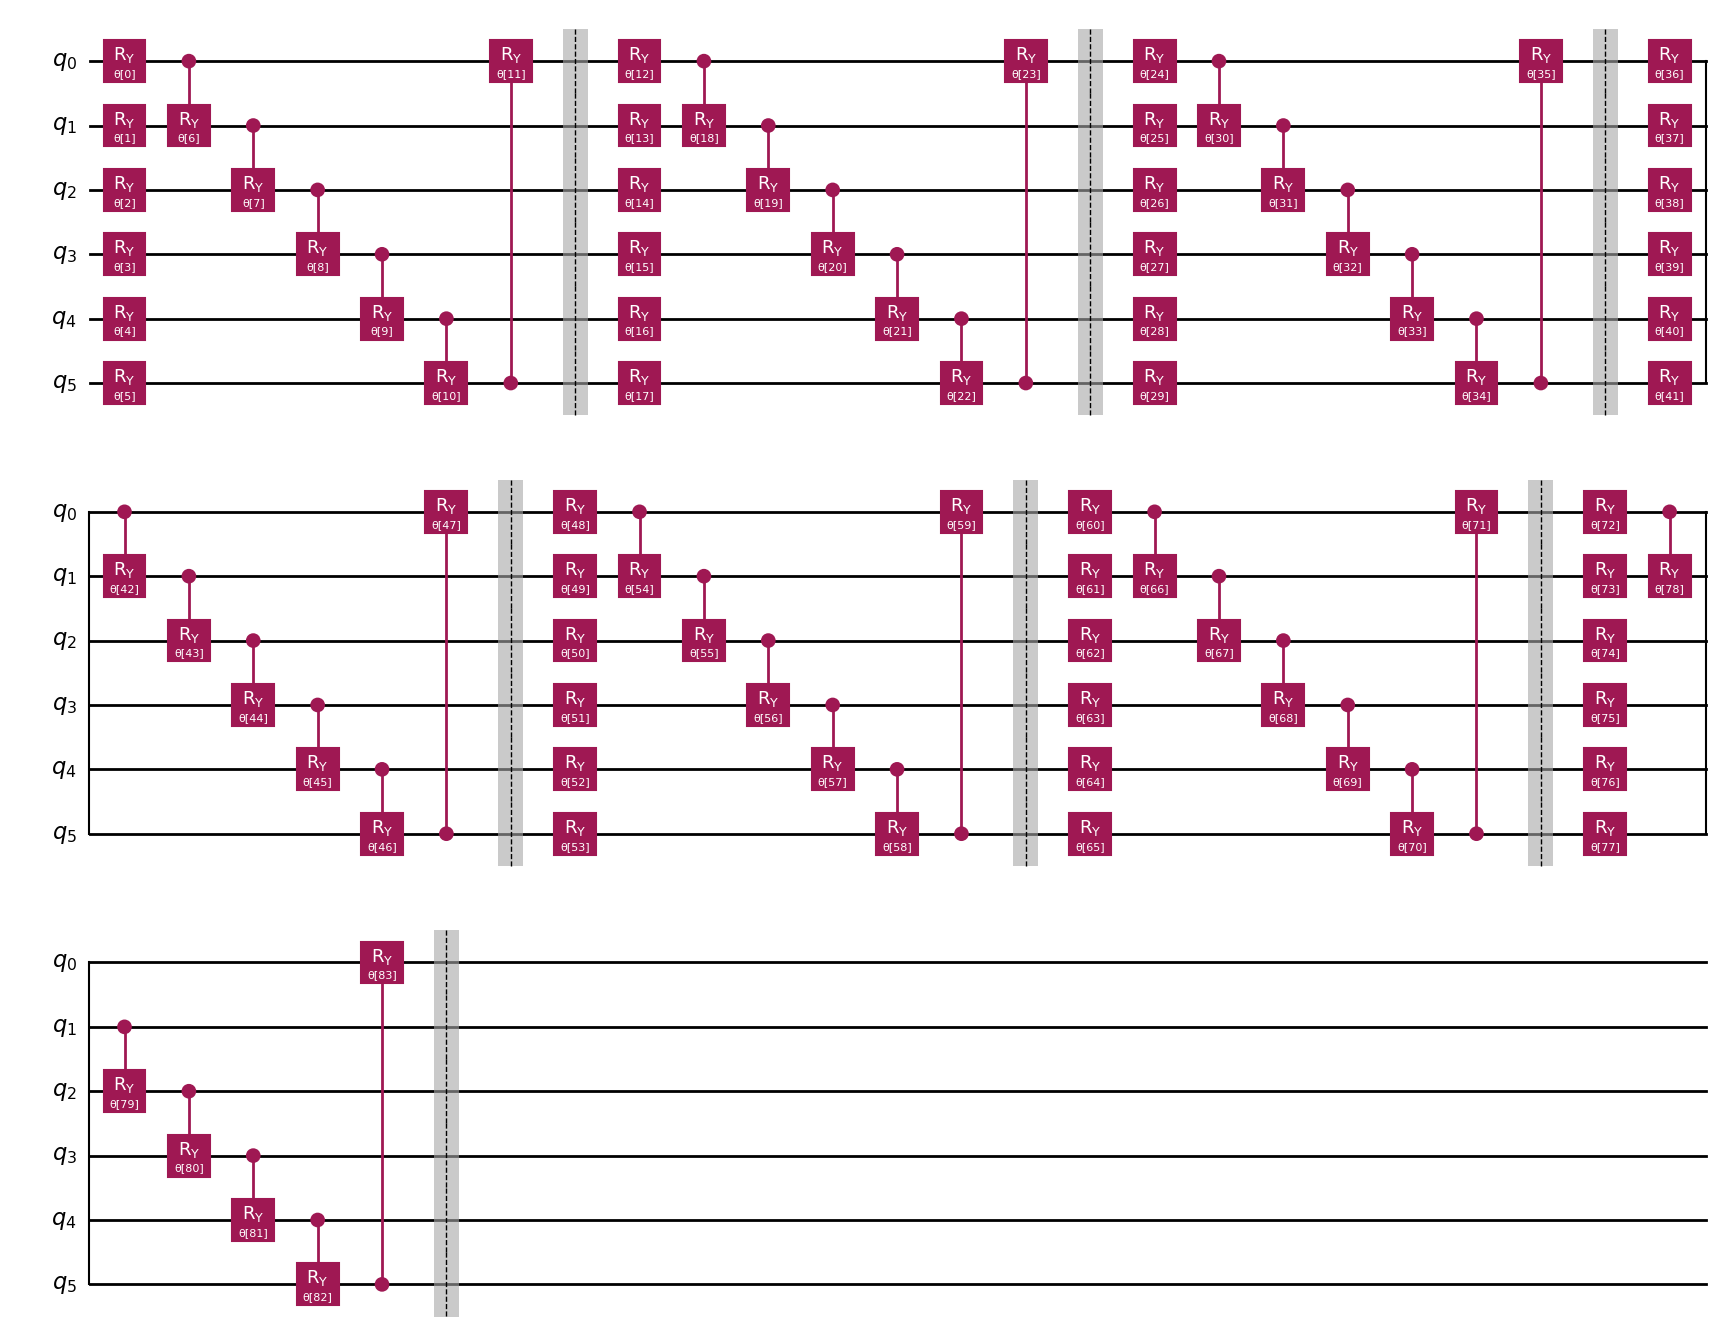

In [64]:
qc_app, training_params = build_app_circuit(number_of_qubits, 7)
qc_app.draw('mpl')

---------------------------------------------
### 2.2 Loss Functions, Optimizers, Wrappers 
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

#### Full global fidelity loss

**Global Fidelity Loss (Mathematical Explanation)**

Let the target quantum state be

$$
|\psi_{\text{target}}\rangle,
$$

and let the variational circuit with parameters (theta) produce the state

$$
|\psi(\theta)\rangle.
$$

The fidelity between these two states is defined as

$$
F(\theta)
= \left| \langle \psi_{\text{target}} \mid \psi(\theta) \rangle \right|^2.
$$

The inner product

$$
\langle \psi_{\text{target}} \mid \psi(\theta) \rangle
$$

is the complex overlap between the two statevectors.

We convert fidelity into a loss function to minimize:

$$
L(\theta)
= 1 - F(\theta)
= 1 - \left| \langle \psi_{\text{target}} \mid \psi(\theta) \rangle \right|^2.
$$

Thus, minimizing $L(\boldsymbol{\theta})$ is equivalent to maximizing fidelity with the target state.


In [65]:
def loss_fidelity(params):
    # assign theta[i] = params[i]
    assignment = {training_params[i]: params[i] for i in range(len(training_params))}
    
    # get the output statevector
    sv = Statevector.from_instruction(qc_app.assign_parameters(assignment))
    
    # compute overlap <target | sv>
    overlap = np.vdot(target.data, sv.data)
    
    # fidelity loss = 1 - |<target|sv>|^2
    return 1 - np.abs(overlap)**2

#### Local RDM loss

To avoid comparing full \(2^N\)-dimensional quantum states, we use a
local loss that matches only a small subset of qubits.

1. Prepare the circuit output state  
   $$|\psi_\theta\rangle.$$

2. Choose a subset of qubits  
   $$S \subset \{0,1,\dots,N-1\}.$$

3. Compute the reduced density matrix (RDM) by tracing out all other qubits:  
   $$
   \rho_\theta^{(S)}
   = \mathrm{Tr}_{\bar S}\!\left(
     |\psi_\theta\rangle\langle\psi_\theta|
   \right).
   $$

4. Compute the same RDM for the target state:  
   $$
   \rho_{\text{target}}^{(S)}.
   $$

5. Compare the two RDMs using fidelity  
   $$
   F =
   F\!\left(
       \rho_\theta^{(S)},
       \rho_{\text{target}}^{(S)}
   \right).
   $$

6. Define the local loss  
   $$
   L = 1 - F.
   $$

This loss measures how well the circuit reproduces the local structure of
the target state on subset \(S\),


In [66]:
from qiskit.quantum_info import partial_trace, state_fidelity

def local_rdm_loss(params, subset):
    """
    Compute 1 - F(local reduced density matrix, target RDM)
    subset: list of qubit indices to keep, e.g. [0] for 1-qubit, [0,1] for 2-qubit
    """
    # assign theta
    assignment = {training_params[i]: params[i] for i in range(len(training_params))}

    # statevector of your approximate circuit
    sv = Statevector.from_instruction(qc_app.assign_parameters(assignment))

    # trace out all qubits not in subset
    trace_out = [q for q in range(qc_app.num_qubits) if q not in subset]
    rho = partial_trace(sv, trace_out)

    # target RDM (same subset)
    target_rho = partial_trace(target, trace_out)

    # local RDM fidelity loss
    return 1 - state_fidelity(rho, target_rho)


#### Numerical gradient

Numerical gradient (central difference)

For a loss function $L(\boldsymbol{\theta})$, the $i$-th component of the gradient is approximated as

$$
\frac{\partial L}{\partial \theta_i}
\approx
\frac{L(\boldsymbol{\theta} + \delta e_i) - L(\boldsymbol{\theta} - \delta e_i)}{2\delta},
$$

where $e_i$ is the unit vector for the $i$-th parameter and $\delta$ is a small step size.


In [67]:
def numerical_grad(loss_fn, params, delta=1e-5):
    grads = np.zeros_like(params)
    for i in range(len(params)):
        p_plus = params.copy();  p_plus[i] += delta
        p_minus = params.copy(); p_minus[i] -= delta
        grads[i] = (loss_fn(p_plus) - loss_fn(p_minus)) / (2 * delta)
    return grads


#### LBFGSB Optimization

(Very basic explanation as it is implemented by scipy already)

The search direction is computed as

$$
p_k = - H_k \, \nabla L(\theta_k),
$$

where $H_k$ is the limited-memory inverse Hessian approximation updated using

$$
s_k = \theta_k - \theta_{k-1}, 
\qquad
y_k = \nabla L(\theta_k) - \nabla L(\theta_{k-1}).
$$

The parameter update is

$$
\theta_{k+1} = \theta_k + \alpha_k p_k,
$$

where $\alpha_k$ is a line-search step size.

The method supports box constraints on parameters (the “B” in L-BFGS-B).



In [68]:
from scipy.optimize import minimize

def optimize_with_lbfgsb(loss_fn, initial_params, global_fidelity_fn, maxiter=400):
    iteration = {"count": 0} 
    def callback(params):
        iteration["count"] += 1
        fidelity = global_fidelity_fn(params)
        print(f"Iteration {iteration['count']}: Global fidelity = {fidelity:.10f}")
    
    result = minimize(
        fun=loss_fn,
        x0=initial_params,
        jac=lambda p: numerical_grad(loss_fn, p, delta=1e-5),
        method="L-BFGS-B",
        callback = callback,
        options={
            "maxiter": maxiter,
            "disp": True
        }
    )
    return result


#### Sparse Amplitude Loss

Given a target quantum state

$$
|\psi_{\text{target}}\rangle
\quad\Longrightarrow\quad
\text{amplitudes } \psi_i,
$$

and a circuit-generated approximate state

$$
|\psi(\theta)\rangle
\quad\Longrightarrow\quad
\text{amplitudes } \phi_i(\theta),
$$

we select a subset of basis indices

$$
S \subset \{0,1,\dots,2^n - 1\}.
$$

The sparse amplitude loss compares only the amplitudes in this subset:

$$
L(\theta)
= \frac{1}{|S|}
\sum_{i \in S}
\left|\phi_i(\theta) - \psi_i\right|^2.
$$

This is a **mean squared error (MSE)** computed on a *small subset* of amplitudes rather than the full statevector,  
acting as a stochastic, low-cost approximation of the full amplitude loss.


In [69]:
def make_sparse_amplitude_loss(amplitude_indices):
    """
    Build a sparse amplitude MSE loss on a fixed subset of basis indices.

    amplitude_indices: 1D array-like of integer basis indices (0 .. 2^n - 1)
    """
    idx = np.array(amplitude_indices, dtype=int)
    idx = np.unique(idx)  # remove duplicates, however, this can reduce the number of amplitudes used

    def loss_sparse(params):
        # assign theta[i] = params[i]
        assignment = {training_params[i]: params[i] for i in range(len(training_params))}

        # output statevector for current parameters
        sv = Statevector.from_instruction(qc_app.assign_parameters(assignment))

        # difference only on selected amplitudes
        diff = sv.data[idx] - target.data[idx]

        # mean squared error on this subset (scaling doesn't matter for argmin)
        return float(np.mean(np.abs(diff) ** 2))

    return loss_sparse


#### ADAM Optimization


**First moment estimate (momentum)**

$$
m_t = \beta_1 m_{t-1} + (1 - \beta_1)\, g_t
$$



**Second moment estimate (RMS)**

$$
v_t = \beta_2 v_{t-1} + (1 - \beta_2)\, g_t^2
$$



**Bias-corrected estimates**

$$
\hat{m}_t = \frac{m_t}{1 - \beta_1^t}
$$

$$
\hat{v}_t = \frac{v_t}{1 - \beta_2^t}
$$

Bias correction removes the initialization bias from \(m_t\) and \(v_t\).



**Parameter update rule**

$$
\theta_{t+1}
= \theta_t
- \alpha \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}
$$




In [70]:
class Adam:
    def __init__(self, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.m = None
        self.v = None
        self.t = 0 # iteration counter

    def step(self, params, grads):
        if self.m is None:
            self.m = np.zeros_like(params)
            self.v = np.zeros_like(params)

        self.t += 1
        self.m = self.beta1 * self.m + (1 - self.beta1) * grads # momentum and RMS
        self.v = self.beta2 * self.v + (1 - self.beta2) * (grads * grads)

        m_hat = self.m / (1 - self.beta1 ** self.t) # bias correction
        v_hat = self.v / (1 - self.beta2 ** self.t)

        updated = params - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)
        return updated


Defining the call function for local sparse looss with ADAM 

In [71]:
def random_subset_fidelity_training_adam(
    initial_params,
    num_cycles,
    block_size,
    batch_size_amplitudes,
    lr=0.01,
    delta=1e-5,
    seed=0
):
    rng = np.random.default_rng(seed)
    params = initial_params.copy()
    num_params = len(params)
    dim = 2 ** qc_app.num_qubits

    optimizer = Adam(lr=lr)
    history = []

    for cycle in range(num_cycles):

        # 1. Random amplitude subset S
        # allow static int, list schedule, or callable schedule
        if callable(batch_size_amplitudes):
            batch_size = batch_size_amplitudes(cycle)  # function schedule
        elif isinstance(batch_size_amplitudes, (list, tuple, np.ndarray)):
            batch_size = batch_size_amplitudes[cycle]  # list schedule
        else:
            batch_size = batch_size_amplitudes         # static integer

        batch = min(batch_size, dim)

        amplitude_indices = rng.choice(dim, size=batch, replace=False)
        sparse_loss = make_sparse_amplitude_loss(amplitude_indices) # insert the randomly chosen indices
        # this sparse_loss now fixed for only a set of random indices chosen from above
        
        # 2. Random subset of parameters B
        if block_size >= num_params:
            block = np.arange(num_params)
        else:
            block = rng.choice(num_params, size=block_size, replace=False)
        block = np.sort(block)

        # 3. Restrict the loss to just params in B (relevant if train with a random subset of thetas)
        def block_loss(block_params):
            full = params.copy()
            full[block] = block_params  # update the chosen active params to get the loss 
            return sparse_loss(full)

        # 4. Compute gradient on this block
        block_params = params[block].copy()
        block_grads = numerical_grad(block_loss, block_params, delta=delta)

        # 5. Adam update only on that block
        updated_block = optimizer.step(block_params, block_grads) # run ADAM once on the block of thetas
        params[block] = updated_block # update the current params

        # 6. Logging
        s_loss = sparse_loss(params)
        try:
            g_loss = loss_fidelity(params)
        except:
            g_loss = None

        print(
            f"Cycle {cycle+1:3d}/{num_cycles} | "
            f"S={batch:2d} | "
            f"sparse_loss={s_loss:.3e} | "
            f"global_loss={g_loss:.3e}"
        )

        history.append({
            "params": params.copy(),
            "block_indices": block.copy(),
            "amplitudes": amplitude_indices.copy(),
            "sparse_loss": s_loss,
            "global_loss": g_loss
        })

    return params, history


#### Random RDM Trainer Adam

In [72]:
from itertools import combinations

def cycle_pairs(n):
    """Infinite generator cycling through all 2-qubit pairs."""
    pair_list = list(combinations(range(n), 2))
    idx = 0
    while True:
        yield list(pair_list[idx])
        idx = (idx + 1) % len(pair_list)

In [73]:
class RDMTrainerAdam:
    def __init__(
        self, 
        qc_app, 
        local_rdm_loss, 
        loss_fidelity,
        default_lr=0.01,
        default_delta=1e-5,
    ):
        """
        qc_app: QuantumCircuit for simulation
        local_rdm_loss: function(params, subset) -> local RDM loss
        loss_fidelity: function(params) -> global fidelity loss
        default_lr: fallback learning rate
        default_delta: fallback finite-difference step
        """
        self.qc_app = qc_app
        self.local_rdm_loss = local_rdm_loss
        self.loss_fidelity = loss_fidelity
        self.default_lr = default_lr
        self.default_delta = default_delta

    # ---------------------------------------------------------
    # Utility: finite-difference gradient
    # ---------------------------------------------------------
    def grad(self, fn, x, delta):
        return numerical_grad(fn, x, delta=delta)

    # ---------------------------------------------------------
    # Utility: one Adam update step
    # ---------------------------------------------------------
    def adam_step(self, optimizer, params, block, block_loss_fn, delta):
        block_params = params[block].copy()
        block_grads = self.grad(block_loss_fn, block_params, delta=delta)
        updated = optimizer.step(block_params, block_grads)
        params[block] = updated
        return params

    # ---------------------------------------------------------
    # Generic training loop (used by all methods)
    # ---------------------------------------------------------
    def _train(
        self,
        initial_params,
        num_cycles,
        block_size,
        subset_generator,
        rng,
        lr,
        delta,
    ):
        params = initial_params.copy()
        num_params = len(params)
        optimizer = Adam(lr=lr)
        history = []

        for cycle in range(num_cycles):

            # --- 1. Choose subset (1q, 2q, 3q, or RR) ---
            subset = subset_generator(rng)

            sparse_loss = lambda p: self.local_rdm_loss(p, subset=subset)

            # --- 2. Random parameter-block selection ---
            if block_size >= num_params:
                block = np.arange(num_params)
            else:
                block = np.sort(rng.choice(num_params, block_size, replace=False))

            # --- 3. Block-restricted loss ---
            def block_loss(block_params):
                full = params.copy()
                full[block] = block_params
                return sparse_loss(full)

            # --- 4. Adam update ---
            params = self.adam_step(optimizer, params, block, block_loss, delta)

            # --- 5. Compute losses ---
            local_loss_value = sparse_loss(params)

            try:
                global_loss_value = self.loss_fidelity(params)
            except Exception:
                global_loss_value = None

            # --- 6. Print progress ---
            print(
                f"Cycle {cycle+1:4d}/{num_cycles} | "
                f"subset={subset} | "
                f"local_loss={local_loss_value:.3e} | "
                f"global_loss={global_loss_value:.3e}"
            )

            # --- 7. Store history ---
            history.append({
                "params": params.copy(),
                "subset": subset,
                "local_loss": local_loss_value,
                "global_loss": global_loss_value,
                "block": block.copy(),
            })

        return params, history

    # =========================================================
    # PUBLIC TRAINING MODES
    # =========================================================

    # ---------------------------------------------------------
    # 1-qubit local RDM training
    # ---------------------------------------------------------
    def train_1q(
        self,
        initial_params,
        num_cycles,
        block_size,
        seed=0,
        lr=None,
        delta=None,
    ):
        rng = np.random.default_rng(seed)
        lr = lr if lr is not None else self.default_lr
        delta = delta if delta is not None else self.default_delta

        return self._train(
            initial_params,
            num_cycles,
            block_size,
            subset_generator=lambda rng: [int(rng.integers(0, self.qc_app.num_qubits))],
            rng=rng,
            lr=lr,
            delta=delta,
        )

    # ---------------------------------------------------------
    # 2-qubit random local RDM training
    # ---------------------------------------------------------
    def train_2q(
        self,
        initial_params,
        num_cycles,
        block_size,
        seed=0,
        lr=None,
        delta=None,
    ):
        rng = np.random.default_rng(seed)
        lr = lr if lr is not None else self.default_lr
        delta = delta if delta is not None else self.default_delta

        return self._train(
            initial_params,
            num_cycles,
            block_size,
            subset_generator=lambda rng: rng.choice(
                self.qc_app.num_qubits, size=2, replace=False
            ).tolist(),
            rng=rng,
            lr=lr,
            delta=delta,
        )

    # ---------------------------------------------------------
    # 3-qubit random local RDM training
    # ---------------------------------------------------------
    def train_3q(
        self,
        initial_params,
        num_cycles,
        block_size,
        seed=0,
        lr=None,
        delta=None,
    ):
        if self.qc_app.num_qubits < 3:
            raise ValueError("Need at least 3 qubits in qc_app.")

        rng = np.random.default_rng(seed)
        lr = lr if lr is not None else self.default_lr
        delta = delta if delta is not None else self.default_delta

        return self._train(
            initial_params,
            num_cycles,
            block_size,
            subset_generator=lambda rng: np.sort(
                rng.choice(self.qc_app.num_qubits, size=3, replace=False)
            ).tolist(),
            rng=rng,
            lr=lr,
            delta=delta,
        )

    # ---------------------------------------------------------
    # Deterministic round-robin 2-qubit pairs
    # ---------------------------------------------------------
    def train_roundrobin_2q(
        self,
        initial_params,
        num_cycles,
        block_size,
        lr=None,
        delta=None,
    ):
        rng = np.random.default_rng(make_seed("roundrobin_rng"))
        lr = lr if lr is not None else self.default_lr
        delta = delta if delta is not None else self.default_delta

        gen = cycle_pairs(self.qc_app.num_qubits)
        subset_fn = lambda rng: next(gen)

        return self._train(
            initial_params,
            num_cycles,
            block_size,
            subset_generator=subset_fn,
            rng=rng,
            lr=lr,
            delta=delta,
        )


In [74]:
trainer = RDMTrainerAdam(
    qc_app=qc_app,
    local_rdm_loss=local_rdm_loss,
    loss_fidelity=loss_fidelity,
    default_lr=0.01,
    default_delta=1e-5
)

#### RDM Mean Loss Function + Trainer

In [75]:
from itertools import combinations

def make_kq_rdm_loss(k):
    """
    Generic RDM loss builder.
    Returns a function(params) that computes the mean k-qubit RDM loss.
    
    Example:
        loss_fn = make_kq_rdm_loss(2)
        loss_fn(params)   -> avg 2q RDM loss
    """
    def loss_fn(params):
        N = qc_app.num_qubits
        subsets = combinations(range(N), k)
        
        losses = []
        for subset in subsets:
            subset = list(subset)        # convert tuple -> list
            losses.append(local_rdm_loss(params, subset=subset))

        return np.mean(losses)
    
    return loss_fn


In [76]:
loss_1q_mean = make_kq_rdm_loss(1)
loss_2q_mean = make_kq_rdm_loss(2)
loss_3q_mean = make_kq_rdm_loss(3)

In [77]:
def train_rdm_lbfgsb(
    initial_params,
    loss_fn,
    maxiter=400,
    label="RDM"
):
    """
    Generic LBFGSB trainer for ANY RDM loss function.

    Args:
        initial_params  : vector of θ
        loss_fn         : function(params) -> scalar loss
        maxiter         : LBFGSB iterations
        label           : name for printing ("1q", "2q", "3q"...)
    """

    result = optimize_with_lbfgsb(
        loss_fn=loss_fn,
        initial_params=initial_params,
        global_fidelity_fn=loss_fidelity,
        maxiter=maxiter
    )

    final_params = result.x

    # compute final RDM loss
    final_loss = loss_fn(final_params)

    # compute global fidelity if available
    try:
        global_loss = loss_fidelity(final_params)
    except Exception:
        global_loss = None

    print(f"\n=== {label} LBFGSB Training Finished ===")
    print(f"Final {label} loss: {final_loss:.6e}")
    print(f"Global fidelity loss: {global_loss:.6e}")

    return final_params, result


---------------------------------------------
### 2.3 Initial parameters generation
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [78]:
def generate_initial_params(num_params, low=0.0, high=2*np.pi, seed=None):
    rng = np.random.default_rng(seed)   
    return rng.uniform(low, high, num_params)

In [79]:
initial_params = generate_initial_params(len(training_params), seed=make_seed("initial data generation"))

---------------------------------------------
### 2.4 Fancy Global Loss methods
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

#### Method 1: Main training using ADAM and Global Sparse Amplitude MSE

Step 1: Do local loss training for a fixed block size as the main training part.
        By training local loss, barren plateau is avoided.
        
Step 2: Final polishing by training the global loss. 
        As the circuit is no longer random at this point, barren plateau doesn't occur.

In [80]:
optimized_params1, training_history1 = random_subset_fidelity_training_adam(
    initial_params,
    num_cycles=20,     
    block_size=30,
    batch_size_amplitudes=32,
    lr=0.05,
    delta=1e-3,
    seed=make_seed("Global Sparse Amplitude MSE Method 1")
)

Cycle   1/20 | S=32 | sparse_loss=2.696e-02 | global_loss=9.942e-01
Cycle   2/20 | S=32 | sparse_loss=3.142e-02 | global_loss=9.968e-01
Cycle   3/20 | S=32 | sparse_loss=3.623e-02 | global_loss=9.970e-01
Cycle   4/20 | S=32 | sparse_loss=2.895e-02 | global_loss=9.978e-01
Cycle   5/20 | S=32 | sparse_loss=2.651e-02 | global_loss=9.982e-01
Cycle   6/20 | S=32 | sparse_loss=4.087e-02 | global_loss=9.990e-01
Cycle   7/20 | S=32 | sparse_loss=2.274e-02 | global_loss=9.994e-01
Cycle   8/20 | S=32 | sparse_loss=2.994e-02 | global_loss=9.996e-01
Cycle   9/20 | S=32 | sparse_loss=2.537e-02 | global_loss=9.997e-01
Cycle  10/20 | S=32 | sparse_loss=2.939e-02 | global_loss=9.999e-01
Cycle  11/20 | S=32 | sparse_loss=3.874e-02 | global_loss=9.999e-01
Cycle  12/20 | S=32 | sparse_loss=2.434e-02 | global_loss=1.000e+00
Cycle  13/20 | S=32 | sparse_loss=3.133e-02 | global_loss=1.000e+00
Cycle  14/20 | S=32 | sparse_loss=2.674e-02 | global_loss=9.999e-01
Cycle  15/20 | S=32 | sparse_loss=2.125e-02 | gl

In [81]:
# find index of entry with smallest global_loss
best_idx = np.argmin([entry["global_loss"] for entry in training_history1])

best_cycle = best_idx + 1  # +1 because cycles were printed starting from 1
best_loss  = training_history1[best_idx]["global_loss"]
best_params = training_history1[best_idx]["params"]

print("Best cycle:", best_cycle)
print("Best global_loss:", best_loss)

Best cycle: 1
Best global_loss: 0.9942254536165446


##### Polish/Final Training Step with Global Fidelity Loss

In [82]:
result_app1 = optimize_with_lbfgsb(loss_fidelity, best_params, loss_fidelity, maxiter=5)

print("Optimal parameters:", result_app1.x)
print("Final loss:", result_app1.fun)

Iteration 1: Global fidelity = 0.9075885406
Iteration 2: Global fidelity = 0.8322731183
Iteration 3: Global fidelity = 0.7636526568
Iteration 4: Global fidelity = 0.6626681054
Iteration 5: Global fidelity = 0.5595228284
Optimal parameters: [2.06271619 1.55759153 3.25050441 2.6706943  1.49860918 1.77215403
 2.33523812 4.57624693 0.4555296  2.07792603 4.77412741 5.16124335
 2.3663489  5.81922201 4.32340188 4.37593518 4.38696404 5.44990273
 5.12368307 6.1171471  5.45399087 2.86753723 5.77367319 1.63198762
 4.6549908  3.41341834 3.92102809 4.58425661 5.18537859 2.55720674
 3.48077247 5.19834974 3.44598302 4.56903899 3.90198819 4.98523488
 4.30663914 6.11603138 6.35296058 0.43202913 4.410094   0.36480108
 2.54977184 2.72495942 5.54113855 3.58751029 0.17388684 0.30110715
 0.72244995 5.29586947 5.8966315  1.2470073  4.92658556 1.9850787
 6.20957586 2.76360997 1.06935546 0.10230614 0.80083719 3.19899887
 6.17667854 1.61226476 1.74783304 1.37132766 4.23330173 2.27255329
 1.71983715 6.37685826 2

#### Method 2 Progressive Fidelity Training / Annealed Sampling

Helper function to create the schedule for the number of amplitudes used for training

In [83]:
def get_subset_size_for_cycle(cycle): # modified this to change how the schedule work
    if cycle < 5:
        return 8
    elif cycle < 10:
        return 16
    elif cycle < 15:
        return 24
    elif cycle < 20:
        return 32
    else:
        return 64


In [84]:
optimized_params2, training_history2 = random_subset_fidelity_training_adam(
    initial_params,
    num_cycles=25,     
    block_size=30,
    batch_size_amplitudes=get_subset_size_for_cycle,
    lr=0.05,
    delta=1e-3,
    seed=make_seed("Global Loss Sparse Amplitude MSE with Schedule")
)


Cycle   1/25 | S= 8 | sparse_loss=2.402e-02 | global_loss=9.914e-01
Cycle   2/25 | S= 8 | sparse_loss=6.177e-02 | global_loss=9.941e-01
Cycle   3/25 | S= 8 | sparse_loss=2.383e-02 | global_loss=9.964e-01
Cycle   4/25 | S= 8 | sparse_loss=7.036e-02 | global_loss=9.975e-01
Cycle   5/25 | S= 8 | sparse_loss=3.946e-02 | global_loss=9.987e-01
Cycle   6/25 | S=16 | sparse_loss=2.987e-02 | global_loss=9.986e-01
Cycle   7/25 | S=16 | sparse_loss=2.576e-02 | global_loss=9.990e-01
Cycle   8/25 | S=16 | sparse_loss=3.235e-02 | global_loss=9.989e-01
Cycle   9/25 | S=16 | sparse_loss=2.716e-02 | global_loss=9.992e-01
Cycle  10/25 | S=16 | sparse_loss=3.224e-02 | global_loss=9.991e-01
Cycle  11/25 | S=24 | sparse_loss=4.192e-02 | global_loss=9.993e-01
Cycle  12/25 | S=24 | sparse_loss=2.446e-02 | global_loss=9.995e-01
Cycle  13/25 | S=24 | sparse_loss=4.338e-02 | global_loss=9.996e-01
Cycle  14/25 | S=24 | sparse_loss=3.840e-02 | global_loss=9.999e-01
Cycle  15/25 | S=24 | sparse_loss=3.747e-02 | gl

In [85]:
# find index of entry with smallest global_loss
best_idx = np.argmin([entry["global_loss"] for entry in training_history2])

best_cycle = best_idx + 1  # +1 because cycles were printed starting from 1
best_loss  = training_history2[best_idx]["global_loss"]
best_params = training_history2[best_idx]["params"]

print("Best cycle:", best_cycle)
print("Best global_loss:", best_loss)

Best cycle: 1
Best global_loss: 0.9913620093222825


In [86]:
result_app2 = optimize_with_lbfgsb(loss_fidelity, best_params, loss_fidelity, maxiter=5)

print("Optimal parameters:", result_app2.x)
print("Final loss:", result_app2.fun)

Iteration 1: Global fidelity = 0.8954501648
Iteration 2: Global fidelity = 0.8554344498
Iteration 3: Global fidelity = 0.7560370009
Iteration 4: Global fidelity = 0.7035522018
Iteration 5: Global fidelity = 0.5442617235
Optimal parameters: [2.05782568 1.54885038 3.3120173  2.66632912 1.50000097 1.84233442
 2.28896107 4.64496635 0.54524927 2.07863611 4.85314203 5.08407294
 2.43102342 5.74087581 4.38620025 4.3792733  4.3593995  5.3955159
 5.05161701 6.17897421 5.40920818 2.92378013 5.75871712 1.62272182
 4.62765091 3.48386592 3.90156447 4.6614971  5.21313469 2.51270996
 3.49881109 5.17275136 3.53468445 4.5914559  3.92977605 4.97040858
 4.26728884 5.96372854 6.38493356 0.32820443 4.46014519 0.423487
 2.57716804 2.70541488 5.62676117 3.5214774  0.13175016 0.25876081
 0.64196235 5.19971983 5.82427734 1.244366   4.92206752 1.99439014
 6.18428924 2.6734749  1.07297633 0.07467215 0.7712107  3.17732837
 6.20843893 1.545562   1.70367374 1.38780494 4.26172847 2.27816897
 1.67479483 6.38828974 3.0

---------------------------------------------
### 2.5 Local RDM Loss 
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

**How the local loss function is defined for their paper (check paper 3)** 

The paper defines a local fidelity term for qubit \(n\) as
$$
F_{\text{local},n}
=
\langle \psi_{\text{target}} \vert
U^{\dagger} P_n U
\vert \psi_{\text{target}} \rangle ,
$$
where \(U\) is the variational circuit and
$$
P_n = \vert 0 \rangle \langle 0 \vert_n
$$
is the projector onto the $|0\rangle$
 state of qubit \(n\).

Using the identity
$$
\langle \psi \vert A \vert \psi \rangle
=
\mathrm{Tr}\!\bigl(A \, \vert \psi \rangle \langle \psi \vert\bigr),
$$
we can rewrite the fidelity as
$$
F_{\text{local},n}
=
\mathrm{Tr}\!\Bigl(
U \vert \psi_{\text{target}} \rangle
\langle \psi_{\text{target}} \vert U^{\dagger}
\, P_n
\Bigr).
$$

Define the evolved density matrix
$$
\rho^{\text{ansatz}}
=
U \vert \psi_{\text{target}} \rangle
\langle \psi_{\text{target}} \vert U^{\dagger}.
$$
Tracing out all qubits except \(n\) gives the 1-qubit reduced density matrix
$$
\rho_n^{\text{ansatz}}
=
\mathrm{Tr}_{\neq n}\!\bigl(\rho^{\text{ansatz}}\bigr).
$$
Then Eq. (3) becomes
$$
F_{\text{local},n}
=
\mathrm{Tr}\!\bigl(
\rho_n^{\text{ansatz}} \,
\vert 0 \rangle \langle 0 \vert
\bigr)
=
\bigl(\rho_n^{\text{ansatz}}\bigr)_{00}.
$$

Thus, the local cost is an average over qubits:
$$
I_{\text{local}}
=
1 - \frac{1}{N}
\sum_{n=1}^{N}
F_{\text{local},n},
$$
which measures how well each qubit locally matches the target state.

This is directly related to the standard 1-qubit RDM loss used in RDM training.  
There, one compares the ansatz 1-qubit RDM $\rho_n^{\text{ansatz}}$
with the target 1-qubit RDM $\rho_n^{\text{target}}$ via

$$
\mathcal{L}_{\text{RDM}}
=
\frac{1}{N}
\sum_{n=1}^{N}
\left\|
\rho_n^{\text{ansatz}} - \rho_n^{\text{target}}
\right\|_2^2 .
$$
The local loss in the paper is therefore a special case of the RDM loss:  
it only matches the $(0,0)$ element of each 1-qubit RDM, which is = 1 while all other elements of this RDM =0, whereas the full RDM loss matches **all** populations and coherences of the reduced density matrix.


**Note:** Keep in mind that they go from the target state -> all 0 state, which is opposite of what we are doing

#### 2 qubit random RDM loss

In [87]:
optimized_params3, training_history3 = trainer.train_2q(
    initial_params,
    num_cycles=10,     
    block_size=84,
    lr=0.05,
    delta=1e-3,
    seed=make_seed("train_two_q")
)


Cycle    1/10 | subset=[0, 3] | local_loss=9.425e-02 | global_loss=9.954e-01
Cycle    2/10 | subset=[1, 5] | local_loss=1.655e-01 | global_loss=9.970e-01
Cycle    3/10 | subset=[0, 1] | local_loss=1.471e-01 | global_loss=9.945e-01
Cycle    4/10 | subset=[2, 3] | local_loss=2.061e-01 | global_loss=9.910e-01
Cycle    5/10 | subset=[4, 1] | local_loss=1.614e-01 | global_loss=9.852e-01
Cycle    6/10 | subset=[1, 4] | local_loss=1.087e-01 | global_loss=9.794e-01
Cycle    7/10 | subset=[3, 5] | local_loss=1.609e-01 | global_loss=9.845e-01
Cycle    8/10 | subset=[1, 2] | local_loss=1.075e-01 | global_loss=9.885e-01
Cycle    9/10 | subset=[5, 4] | local_loss=1.197e-01 | global_loss=9.930e-01
Cycle   10/10 | subset=[2, 5] | local_loss=4.217e-02 | global_loss=9.974e-01


In [88]:
# find index of entry with smallest global_loss
best_idx = np.argmin([entry["global_loss"] for entry in training_history3])

best_cycle = best_idx + 1  # +1 because cycles were printed starting from 1
best_loss  = training_history3[best_idx]["global_loss"]
best_params = training_history3[best_idx]["params"]

print("Best cycle:", best_cycle)
print("Best global_loss:", best_loss)

Best cycle: 6
Best global_loss: 0.979368986979792


In [89]:
result_app3 = optimize_with_lbfgsb(loss_fidelity, best_params,loss_fidelity, maxiter=5)

print("Optimal parameters:", result_app3.x)
print("Final loss:", result_app3.fun)


Iteration 1: Global fidelity = 0.8262908809
Iteration 2: Global fidelity = 0.7587055433
Iteration 3: Global fidelity = 0.6731218827
Iteration 4: Global fidelity = 0.5855048054
Iteration 5: Global fidelity = 0.5110085032
Optimal parameters: [1.79200431 1.90020004 3.59690084 2.99489306 1.56361738 1.82821607
 2.41380047 4.99327571 0.71260649 2.19326068 4.92996877 5.34382117
 1.90163842 5.77847567 4.58758735 5.22150196 4.70013638 5.20584636
 5.08567666 5.94988521 5.56853297 2.98795485 5.59573739 1.76091945
 5.15469288 3.42338721 3.61250877 4.63346151 4.88995841 2.49024605
 3.50008443 5.20873938 3.61214789 4.29635611 4.38386326 4.67549169
 4.13576004 6.15339875 5.64123245 0.95744868 4.99603923 0.10810267
 2.51775816 2.51491746 6.03710418 4.44620461 0.82329482 0.16832579
 0.62198186 4.84914538 6.17204454 1.24423228 5.19182203 1.6968236
 5.88771283 3.03023095 1.0339549  0.43738277 0.53579653 3.48033165
 5.9981062  1.97921248 1.62061012 1.44956943 3.6369041  2.48124516
 1.39302975 5.46314232 3

#### 1 qubit random RDM local loss

In [90]:
optimized_params4, training_history4 = trainer.train_1q(
    initial_params,
    num_cycles=10,     
    block_size=84,
    lr=0.05,
    delta=1e-3,
    seed=make_seed("train_one_q")
)


Cycle    1/10 | subset=[5] | local_loss=1.074e-02 | global_loss=9.983e-01
Cycle    2/10 | subset=[0] | local_loss=6.673e-03 | global_loss=9.998e-01
Cycle    3/10 | subset=[1] | local_loss=1.241e-01 | global_loss=9.984e-01
Cycle    4/10 | subset=[4] | local_loss=6.175e-03 | global_loss=9.935e-01
Cycle    5/10 | subset=[4] | local_loss=2.094e-03 | global_loss=9.853e-01
Cycle    6/10 | subset=[4] | local_loss=6.043e-03 | global_loss=9.764e-01
Cycle    7/10 | subset=[4] | local_loss=9.253e-03 | global_loss=9.684e-01
Cycle    8/10 | subset=[5] | local_loss=5.349e-02 | global_loss=9.688e-01
Cycle    9/10 | subset=[4] | local_loss=6.512e-03 | global_loss=9.716e-01
Cycle   10/10 | subset=[0] | local_loss=2.298e-02 | global_loss=9.768e-01


#### 3 qubit random RDM local loss 

In [91]:
optimized_params5, training_history5 = trainer.train_3q(
    initial_params,
    num_cycles=10,     
    block_size=84,
    lr=0.05,
    delta=1e-3,
    seed=make_seed("train_three_q")
)


Cycle    1/10 | subset=[1, 2, 5] | local_loss=3.991e-01 | global_loss=9.547e-01
Cycle    2/10 | subset=[0, 2, 4] | local_loss=2.384e-01 | global_loss=9.274e-01
Cycle    3/10 | subset=[0, 1, 3] | local_loss=4.380e-01 | global_loss=9.127e-01
Cycle    4/10 | subset=[0, 1, 3] | local_loss=3.667e-01 | global_loss=9.055e-01
Cycle    5/10 | subset=[1, 2, 3] | local_loss=3.865e-01 | global_loss=8.942e-01
Cycle    6/10 | subset=[1, 2, 4] | local_loss=2.928e-01 | global_loss=8.852e-01
Cycle    7/10 | subset=[0, 1, 5] | local_loss=3.618e-01 | global_loss=8.803e-01
Cycle    8/10 | subset=[1, 4, 5] | local_loss=3.393e-01 | global_loss=8.702e-01
Cycle    9/10 | subset=[3, 4, 5] | local_loss=5.111e-01 | global_loss=8.562e-01
Cycle   10/10 | subset=[0, 2, 4] | local_loss=2.357e-01 | global_loss=8.523e-01


#### Round robin (2 qubits) RDM loss

In [92]:
optimized_params6, training_history6 = trainer.train_roundrobin_2q(
    initial_params,
    num_cycles=10,     
    block_size=84,
    lr=0.05,
    delta=1e-3
)


Cycle    1/10 | subset=[0, 1] | local_loss=1.250e-01 | global_loss=9.818e-01
Cycle    2/10 | subset=[0, 2] | local_loss=1.083e-01 | global_loss=9.544e-01
Cycle    3/10 | subset=[0, 3] | local_loss=2.069e-01 | global_loss=9.329e-01
Cycle    4/10 | subset=[0, 4] | local_loss=4.182e-02 | global_loss=9.207e-01
Cycle    5/10 | subset=[0, 5] | local_loss=7.305e-02 | global_loss=9.252e-01
Cycle    6/10 | subset=[1, 2] | local_loss=1.360e-01 | global_loss=9.200e-01
Cycle    7/10 | subset=[1, 3] | local_loss=1.033e-01 | global_loss=9.115e-01
Cycle    8/10 | subset=[1, 4] | local_loss=1.289e-01 | global_loss=9.066e-01
Cycle    9/10 | subset=[1, 5] | local_loss=9.734e-02 | global_loss=9.075e-01
Cycle   10/10 | subset=[2, 3] | local_loss=1.074e-01 | global_loss=9.125e-01


#### Full 2qubit RDM loss (mean over all values)

In [93]:
optimized_params7, training_history7 = train_rdm_lbfgsb(
    initial_params,
    loss_fn=loss_2q_mean,
    maxiter=10,
    label="2q mean RDM"
)

Iteration 1: Global fidelity = 0.9210803948
Iteration 2: Global fidelity = 0.8635852350
Iteration 3: Global fidelity = 0.8621113490
Iteration 4: Global fidelity = 0.8683879363
Iteration 5: Global fidelity = 0.8651982308
Iteration 6: Global fidelity = 0.8873818573
Iteration 7: Global fidelity = 0.8871963508
Iteration 8: Global fidelity = 0.8794380670
Iteration 9: Global fidelity = 0.8800306888
Iteration 10: Global fidelity = 0.8922298527

=== 2q mean RDM LBFGSB Training Finished ===
Final 2q mean RDM loss: 3.887595e-02
Global fidelity loss: 8.922299e-01


#### Full 1qubit RDM loss (mean over all values)

In [94]:
optimized_params8, training_history8 = train_rdm_lbfgsb(
    initial_params,
    loss_fn=loss_1q_mean,
    maxiter=10,
    label="1q mean RDM"
)

Iteration 1: Global fidelity = 0.9219501129
Iteration 2: Global fidelity = 0.8773820229
Iteration 3: Global fidelity = 0.8864676734
Iteration 4: Global fidelity = 0.8858761365
Iteration 5: Global fidelity = 0.8767974492
Iteration 6: Global fidelity = 0.8895733489
Iteration 7: Global fidelity = 0.8924977478
Iteration 8: Global fidelity = 0.8955286731
Iteration 9: Global fidelity = 0.8954254575
Iteration 10: Global fidelity = 0.8976802206

=== 1q mean RDM LBFGSB Training Finished ===
Final 1q mean RDM loss: 2.155871e-05
Global fidelity loss: 8.976802e-01


#### Full 3qubit RDM loss (mean over all values)

In [95]:
optimized_params9, training_history9 = train_rdm_lbfgsb(
    initial_params,
    loss_fn=loss_3q_mean,
    maxiter=10,
    label="3q mean RDM"
)

Iteration 1: Global fidelity = 0.9137890167
Iteration 2: Global fidelity = 0.8697777062
Iteration 3: Global fidelity = 0.8518973136
Iteration 4: Global fidelity = 0.8228185159
Iteration 5: Global fidelity = 0.8338676390
Iteration 6: Global fidelity = 0.8098543211
Iteration 7: Global fidelity = 0.7925207929
Iteration 8: Global fidelity = 0.7698631905
Iteration 9: Global fidelity = 0.6943556637
Iteration 10: Global fidelity = 0.6883113967

=== 3q mean RDM LBFGSB Training Finished ===
Final 3q mean RDM loss: 2.211263e-01
Global fidelity loss: 6.883114e-01


---------------------------------------------
### 2.6 Reverse method (Best method)
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

#### Circuit builder

Rebuild the qc + qc_app.inverse circuit manually for ease of use. The new parameter to be trained is phi

Note: phi[i] = -theta[i] as we are dealing with real values

In [96]:
from qiskit.circuit import QuantumCircuit, ParameterVector

def build_reverse_circuit_manual(qc_orig, num_qubits, num_layers):
    """
    Build U_rev = U_app(φ)^† U_orig
    using NEW parameters φ.
    """
    m = num_layers * num_qubits * 2
    phi = ParameterVector("φ", m)

    qc_rev = QuantumCircuit(num_qubits)

    # First: apply U_orig
    qc_rev.compose(qc_orig, inplace=True)

    # Then: apply U_app(φ)^† layer by layer, reversed
    for layer in reversed(range(num_layers)):
        base = num_qubits * 2 * layer
        cry_base = base + num_qubits

        # Inverse CRY block
        for q in reversed(range(num_qubits)):
            control = q
            target_qubit = 0 if q == num_qubits - 1 else q + 1
            qc_rev.cry(-phi[cry_base + q], control, target_qubit)

        # Inverse RY block
        for q in reversed(range(num_qubits)):
            qc_rev.ry(-phi[base + q], q)

        qc_rev.barrier()

    return qc_rev, training_params


Insert the number of layers here

In [97]:
qc_reverse, phi = build_reverse_circuit_manual(
    qc,
    number_of_qubits,
    7
)

#### Draw the full reversed circuit

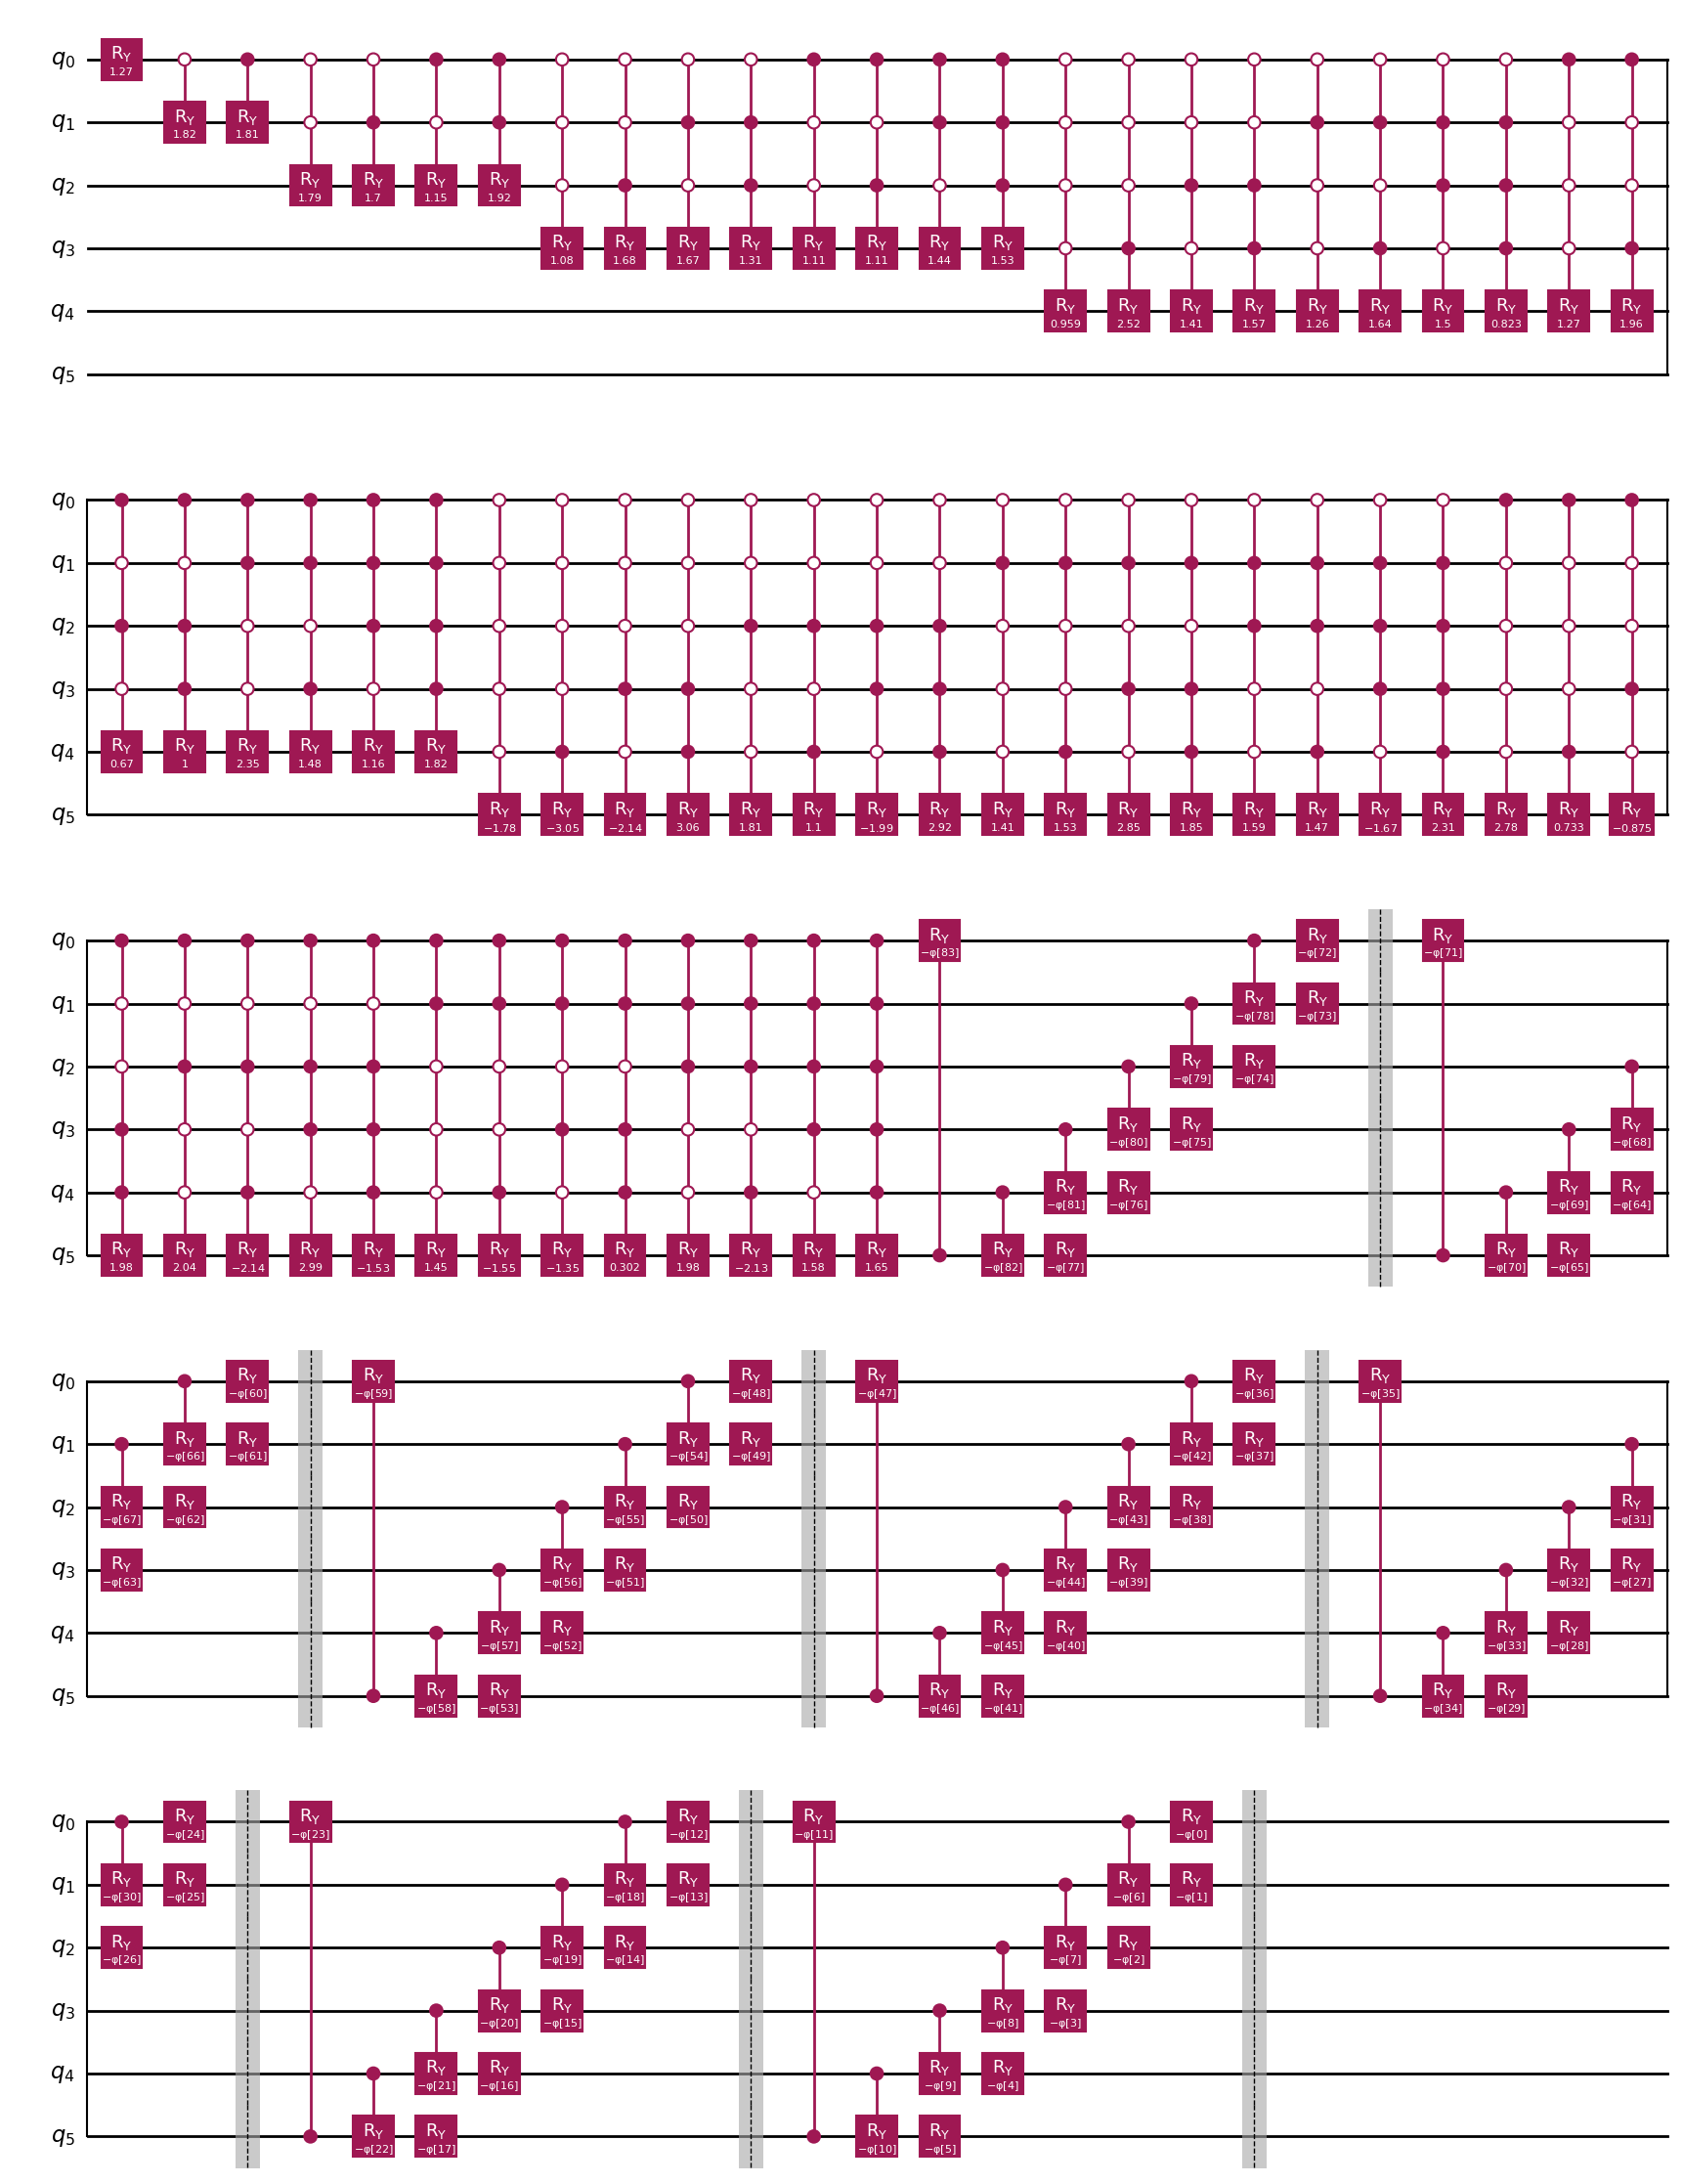

In [98]:
qc_reverse.draw('mpl')

#### 1 Qubit RDM mean loss for reversed circuit + Training wrapper

The exact same thing as the regular version, just with the target RDM always being the matrix [(1 0), (0 0)] (so that every qubit is the 0 state)

In [99]:
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace, state_fidelity
import numpy as np

target_1q_reverse = DensityMatrix([[1, 0],
                           [0, 0]])

def loss_1q_mean_reverse(params):
    assignment = {phi[i]: params[i] for i in range(len(phi))}
    sv = Statevector.from_instruction(qc_reverse.assign_parameters(assignment))

    N = qc_reverse.num_qubits
    losses = []

    for q in range(N):
        trace_out = [i for i in range(N) if i != q]
        rho_q = partial_trace(sv, trace_out)

        # fixed 1-qubit RDM of |0><0|
        losses.append(1 - state_fidelity(rho_q, target_1q_reverse))

    return np.mean(losses)


Exact same thing just with the new qc_reversed circuit

In [100]:
def train_reverse_1q_mean_adam(initial_params, steps=500, lr=0.01, delta=1e-5):
    opt = Adam(lr=lr)
    params = initial_params.copy()
    history = []

    for step in range(steps):
        loss = loss_1q_mean_reverse(params)
        grad = numerical_grad(loss_1q_mean_reverse, params, delta=delta)
        params = opt.step(params, grad)
        
        history.append(loss)
        if step%100 == 0:
            print(f"Step {step:4d} | Loss = {loss:.6f}")

    return params, history


#### Training

The loss here is the mean(1 - fidelity(RDM_1_qubit & target_RDM) ). This loss = 0 means the final state of the circuit is the all 0 state.

In [101]:
initial_phi = generate_initial_params(len(training_params), seed=make_seed("initial data for the reversed circuit"))
trained_phi, history = train_reverse_1q_mean_adam(initial_phi, steps=500)

Step    0 | Loss = 0.485912
Step  100 | Loss = 0.095966
Step  200 | Loss = 0.013561
Step  300 | Loss = 0.003117
Step  400 | Loss = 0.001030


In [114]:
history[-1] # Final local loss

np.float64(0.00036534825108217966)

#### Interpret the result

The final statevector for the full qc_reversed should be [1,0,0,0,...,0] i.e the all 0 state

In [102]:
Statevector.from_instruction(qc_reverse.assign_parameters(trained_phi))

Statevector([-9.99626420e-01-5.80952188e-16j,
             -3.51143797e-04-1.06936364e-16j,
              2.42816461e-03-4.28737153e-17j,
             -9.78761028e-04-1.17076123e-16j,
              2.47107109e-04-4.28686370e-17j,
              4.51009893e-03-6.19802136e-17j,
             -1.60012618e-03-2.58251368e-17j,
             -1.12313937e-03+3.47203168e-17j,
              2.34523069e-04-1.05369899e-17j,
             -9.95217773e-03-2.37892131e-17j,
              2.85900717e-03+3.94448621e-17j,
             -2.04517149e-03+6.87244294e-17j,
             -2.14600371e-03-2.18235499e-16j,
              5.43403058e-03-4.27904185e-17j,
             -2.05226060e-03+8.80182489e-17j,
              3.23398887e-03-1.91443904e-17j,
             -4.01069440e-04-7.46625370e-17j,
              5.25091651e-03-6.63764145e-17j,
             -1.21975382e-03-7.08690478e-18j,
             -5.41048350e-04+7.84547764e-17j,
             -2.24554504e-03+8.06814663e-17j,
              7.53479736e-04+8.746

Insert those parameters into the regular qc_app circuit and you get the approximated encoding

In [103]:
Statevector.from_instruction(qc_app.assign_parameters(trained_phi))

Statevector([-0.15373838+0.j, -0.03698504+0.j, -0.17419857+0.j,
             -0.0561208 +0.j, -0.12496595+0.j, -0.08282153+0.j,
             -0.19265305+0.j, -0.12393143+0.j, -0.02771763+0.j,
             -0.07795961+0.j, -0.03115156+0.j, -0.10588193+0.j,
             -0.1067872 +0.j, -0.01314199+0.j, -0.17905595+0.j,
             -0.11281071+0.j, -0.00547458+0.j, -0.14667206+0.j,
             -0.12152264+0.j, -0.129439  +0.j, -0.14234802+0.j,
             -0.02224723+0.j, -0.18898755+0.j, -0.07359671+0.j,
             -0.0036647 +0.j, -0.07290397+0.j, -0.1343521 +0.j,
             -0.11904453+0.j, -0.03071847+0.j, -0.02841114+0.j,
             -0.04124633+0.j, -0.14439999+0.j,  0.18071793+0.j,
             -0.20781709+0.j, -0.14764469+0.j, -0.04993605+0.j,
             -0.15031563+0.j, -0.13750987+0.j, -0.20074812+0.j,
             -0.19659745+0.j,  0.03962454+0.j,  0.04419069+0.j,
             -0.20957799+0.j,  0.0820852 +0.j,  0.17004079+0.j,
             -0.08744184+0.j,  0.1974874

Check for global fidelity of the trained parameters (the global loss for qc_app circuit)

In [104]:
loss_fidelity(trained_phi)

np.float64(0.0007470201475445748)

---------------------------------------------
### 2.7 Applied the trained params to the approx circuit
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [105]:
optimal_params = trained_phi
trained_qc = qc_app.assign_parameters({training_params[i]: optimal_params[i] for i in range(len(training_params))})

In [106]:
simulator = Aer.get_backend("statevector_simulator")
transpiled_trained_qc = transpile(trained_qc,backend=simulator)
job_trained = simulator.run(transpiled_trained_qc)
result_trained = job_trained.result().get_statevector()


#### Decomposed Variational Circuit Depth

In [107]:
trained_qc.decompose(reps=3).depth()

140

In [108]:
trained_qc.decompose(reps=3).num_nonlocal_gates()

84

#### Result of trained circuit

In [109]:
print(array_to_latex(result_trained, pretext="\\text{Statevector of approximated data} = "))

<IPython.core.display.Math object>

None


<h2 style="color:green; font-weight:bold">3. Reference to check</h2>

1. Inspiration for the circuit:

https://www.researchgate.net/publication/360063326_Quantum_Self-Supervised_Learning

2. Global loss to Local loss prevent barren plateau for shallow parametrized quantum circuits

https://www.nature.com/articles/s41467-021-21728-w

3. Inspiration for the local loss function and the reverse method

https://doi.org/10.1038/s41534-024-00858-1

4. Algorithm for the exact circuit (divide-and-conquer method)

https://arxiv.org/abs/2505.14295